# 02 Reminder experiment analysis
**All data is synthetic; effects were planted by the generator.** Logic lives in `src/experiment.py`; the plan is in `docs/assumptions.md` (A30-A38).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200)
from src import experiment

In [2]:
out = experiment.run()
out['rates'].round(4)

,arm,label,patients_scheduled,patients_resolved,scheduled_appts,resolved_appts,no_shows,no_show_rate,ci_low_cluster,ci_high_cluster
0,control,Control (standard SMS 24h),4421,4382,19135,17617,3870,0.2197,0.2126,0.2268
1,arm_a,Arm A (AI voice 48h + SMS),4239,4210,18717,17265,3215,0.1862,0.1796,0.1929
2,arm_b,Arm B (two-way SMS + reschedule link),4389,4343,19222,17296,3467,0.2005,0.1936,0.2073


## Primary effects (cluster-robust)

In [3]:
e = out['effects']
e[(e.analysis=='primary') & e.method.str.startswith('cluster-robust')][['comparison','metric','estimate','ci_low','ci_high','p_raw','p_holm']].round(4)

,comparison,metric,estimate,ci_low,ci_high,p_raw,p_holm
0,arm_a vs control,risk difference,-0.0335,-0.0432,-0.0237,0.0000,0.0000
1,arm_a vs control,relative risk,0.8477,0.8079,0.8895,0.0000,0.0000
2,arm_a vs control,odds ratio,0.8128,0.7653,0.8633,0.0000,0.0000
3,arm_b vs control,risk difference,-0.0192,-0.0291,-0.0094,0.0001,0.0003
4,arm_b vs control,relative risk,0.9125,0.8706,0.9564,0.0001,0.0003
5,arm_b vs control,odds ratio,0.8906,0.8391,0.9451,0.0001,0.0003
6,arm_a vs arm_b,risk difference,-0.0142,-0.0238,-0.0047,0.0035,0.0035
7,arm_a vs arm_b,relative risk,0.9290,0.8842,0.9760,0.0035,0.0035
8,arm_a vs arm_b,odds ratio,0.9127,0.8585,0.9704,0.0035,0.0035


## Validity: largest covariate imbalances (SMD)

In [4]:
b = out['balance'].assign(abs_smd=lambda t: t['smd'].abs())
b.sort_values('abs_smd', ascending=False).head(10).round(3)

,covariate,arm,mean_arm,mean_control,smd,abs_smd
3,age_band_50-64,arm_a,0.204,0.182,0.057,0.057
22,sdoh_employment,arm_a,0.225,0.203,0.053,0.053
11,language_Other,arm_a,0.076,0.063,0.053,0.053
7,payer_type_Medicare,arm_a,0.114,0.128,-0.043,0.043
0,age_band_18-24,arm_a,0.168,0.184,-0.041,0.041
12,language_Spanish,arm_a,0.121,0.134,-0.040,0.040
23,appts_in_window,arm_a,4.415,4.328,0.038,0.038
21,sdoh_food,arm_a,0.122,0.135,-0.038,0.038
19,sdoh_housing,arm_a,0.114,0.103,0.036,0.036
37,language_Other,arm_b,0.071,0.063,0.033,0.033


## Power

In [5]:
pd.Series(out['power']).to_frame('value')

,value
baseline,0.22
mde_abs,0.02
alpha,0.05
power,0.8
comparisons,3
alpha_holm_first_step,0.016667
pre_period_observed_baseline,0.22114
icc_pre_period,0.083108
m_eff,5.163479
mean_resolved_per_patient,4.033862


## Guardrails

In [6]:
out['guardrails'].round(4)

,guardrail,comparison,rate_control,rate_arm,rd,ci_low,ci_high,p_raw,p_holm,breach
0,Cancellation rate (cancelled / all scheduled),arm_a vs control,0.0793,0.0776,-0.0018,-0.0072,0.0037,0.5269,1.0000,False
1,Cancellation rate (cancelled / all scheduled),arm_b vs control,0.0793,0.1002,0.0209,0.0151,0.0266,0.0000,0.0000,True
2,Late-cancel rate (late cancels / resolved),arm_a vs control,0.0406,0.0395,-0.0011,-0.0052,0.0030,0.6044,1.0000,False
3,Late-cancel rate (late cancels / resolved),arm_b vs control,0.0406,0.0520,0.0114,0.0070,0.0158,0.0000,0.0000,True
4,Non-completion rate (not completed / all sched...,arm_a vs control,0.3189,0.2858,-0.0332,-0.0433,-0.0230,0.0000,0.0000,False
5,Non-completion rate (not completed / all sched...,arm_b vs control,0.3189,0.3273,0.0084,-0.0019,0.0187,0.1095,0.3285,False


## Effects and subgroups

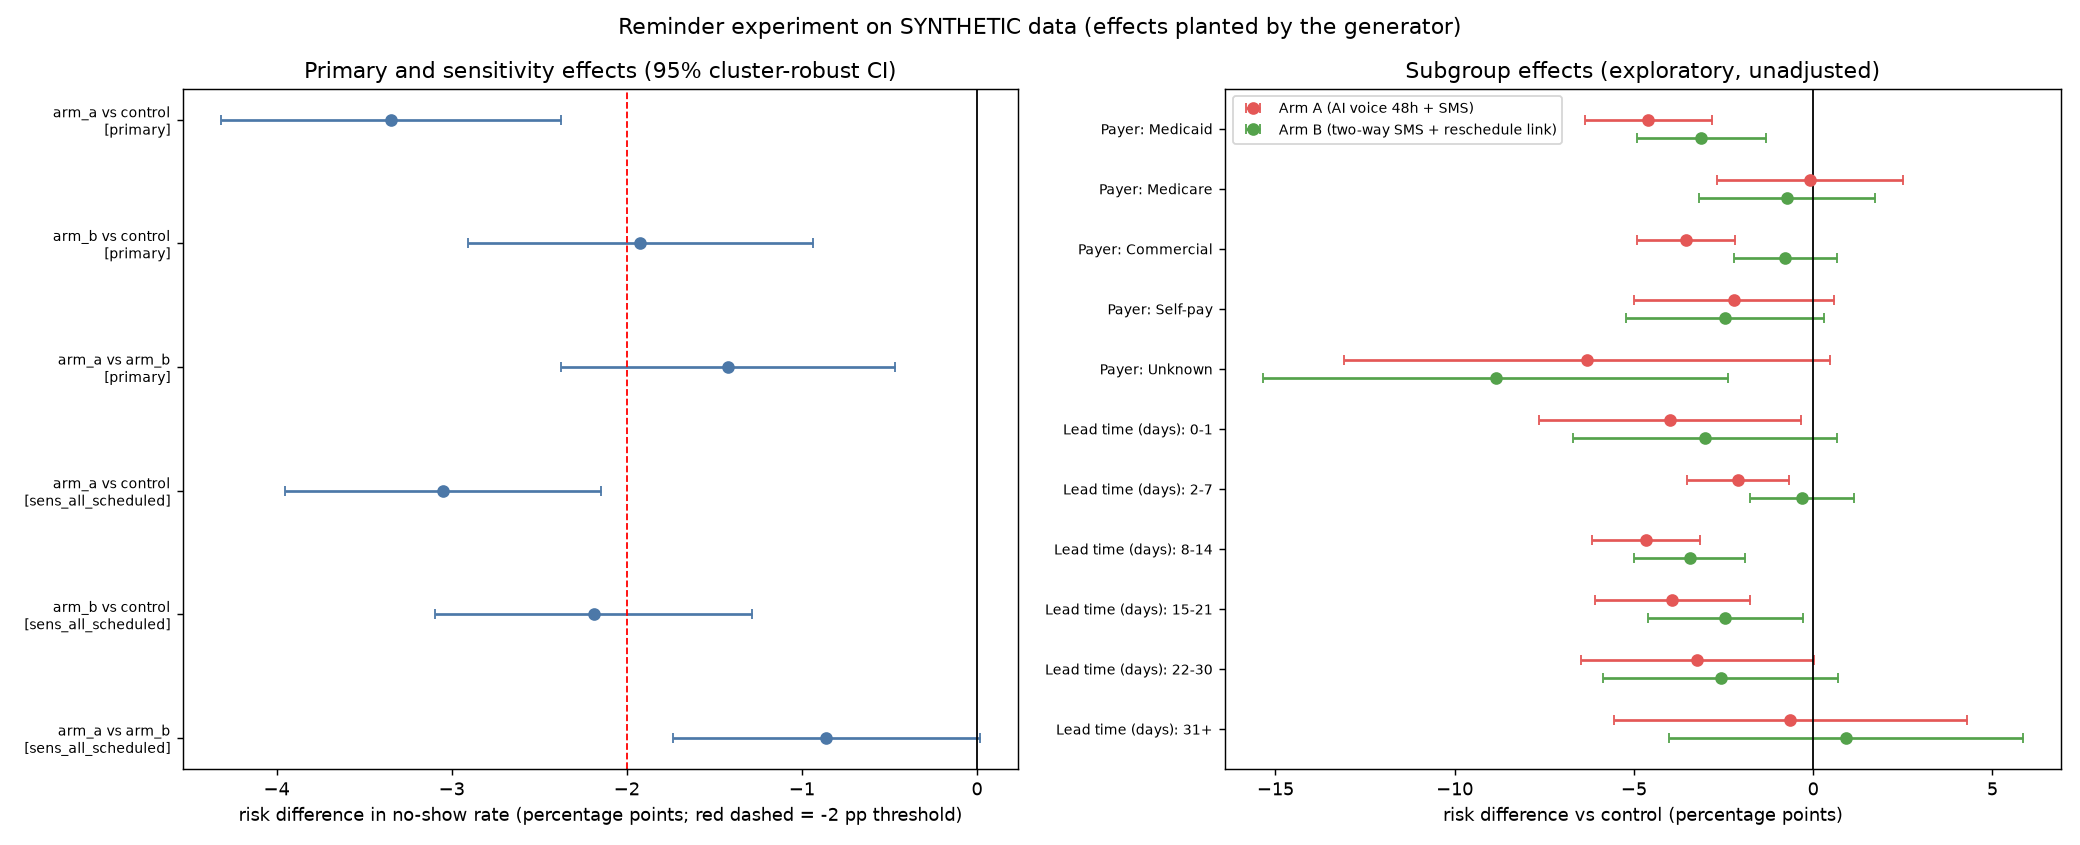

In [7]:
Image(filename=str(experiment.FIGURES / 'experiment_effects.png'))

## Decision memo

In [8]:
Markdown(out['memo'])

# Experiment Readout: AI reminder experiment

> ALL DATA IS SYNTHETIC. The reminder effects (arm A -3.0 pp, arm B -1.5 pp, stronger for Medicaid and long lead times) were PLANTED by src/generate_data.py (assumptions A5, A6, A14). This memo demonstrates the analysis method and the decision rule; it is not a finding about real patients or clinics.

## Decision

| Arm | No-show change vs control (95% CI) | Holm p | Guardrail breaches | Decision |
|---|---|---|---|---|
| Arm A (AI voice 48h + SMS) | -3.35 pp (-4.32 pp to -2.37 pp) | <0.0001 | none | **SHIP** |
| Arm B (two-way SMS + reschedule link) | -1.92 pp (-2.91 pp to -0.94 pp) | 0.0003 | Cancellation rate (cancelled / all scheduled); Late-cancel rate (late cancels / resolved) | **ITERATE** |

Rule (fixed before running, A36): SHIP if Holm p < 0.05, the estimated reduction is at least 2 pp and no guardrail is breached; ITERATE if the reduction is significant but smaller than 2 pp or a guardrail is breached; STOP if there is no significant reduction.

- **Arm A (AI voice 48h + SMS): SHIP** because significant reduction of at least the 2 pp threshold and no guardrail breach.
- **Arm B (two-way SMS + reschedule link): ITERATE** because significant reduction, but the estimated reduction is smaller than the 2 pp practical threshold and guardrail breach: Cancellation rate (cancelled / all scheduled); Late-cancel rate (late cancels / resolved).

## Primary result (resolved appointments; SEs clustered by patient)

| Arm | Patients | Resolved appts | No-show rate (95% CI) |
|---|---|---|---|
| Control (standard SMS 24h) | 4,382 | 17,617 | 22.0% (21.3% to 22.7%) |
| Arm A (AI voice 48h + SMS) | 4,210 | 17,265 | 18.6% (18.0% to 19.3%) |
| Arm B (two-way SMS + reschedule link) | 4,343 | 17,296 | 20.0% (19.4% to 20.7%) |

| Comparison | Risk difference | Relative risk | Odds ratio | p (raw) | p (Holm) |
|---|---|---|---|---|---|
| arm_a vs control | -3.35 pp (-4.32 pp to -2.37 pp) | 0.848 (0.808 to 0.889) | 0.813 (0.765 to 0.863) | <0.0001 | <0.0001 |
| arm_b vs control | -1.92 pp (-2.91 pp to -0.94 pp) | 0.912 (0.871 to 0.956) | 0.891 (0.839 to 0.945) | 0.0001 | 0.0003 |
| arm_a vs arm_b | -1.42 pp (-2.38 pp to -0.47 pp) | 0.929 (0.884 to 0.976) | 0.913 (0.859 to 0.970) | 0.0035 | 0.0035 |

Naive tests that ignore patient clustering (shown to illustrate the optimism):

| Comparison | z-test p | z-test Holm p | chi-square p | chi-square Holm p |
|---|---|---|---|---|
| arm_a vs control | <0.0001 | <0.0001 | <0.0001 | <0.0001 |
| arm_b vs control | <0.0001 | <0.0001 | <0.0001 | <0.0001 |
| arm_a vs arm_b | 0.0008 | 0.0008 | 0.0008 | 0.0008 |

## Validity checks

- **Sample ratio:** assigned patients control 4,426, arm_a 4,241, arm_b 4,392 (chi-square p = 0.1078; no alarm at the 0.001 threshold). Analysed patients control 4,421, arm_a 4,239, arm_b 4,389 (p = 0.1141).
- **Covariate balance:** largest absolute SMD = 0.057 (age_band_50-64, arm_a vs control); 0 of 52 covariate-arm comparisons exceed 0.10.
- **Randomization omnibus (multinomial LR test of arm on baseline covariates):** chi-square = 86.5 on 64 df, p = 0.0320. No alarm threshold was pre-specified for this test (A34). The p-value is below 0.05, so it is reported as a flag: no individual covariate is meaningfully imbalanced (see SMD above) and the covariate-adjusted estimates match the unadjusted ones, but a real trial would investigate the assignment mechanism. In this project arms were assigned by simple random draws, so the result is consistent with chance (one test, 64 df).
- **Assignment integrity:** appointments in the window labelled 'standard': 0; appointments outside the window labelled with an arm: 0; appointments whose arm differs from the patient's assignment: 0.

## Power (planned before looking at effects, A33)

- Required resolved appointments per arm for a 2 pp reduction from a 22% baseline (power 80%): 6,507 at alpha 0.05 if observations were independent; 8,679 at the Holm first-step alpha of 0.0167.
- Pre-experiment ICC = 0.083; design effect = 1.35; so about 11,682 resolved appointments (about 2,896 patients) per arm are required.
- Available: control 17,617, arm_a 17,265, arm_b 17,296 resolved appointments and control 4,382, arm_a 4,210, arm_b 4,343 patients per arm. Smallest detectable reduction at 80% power with the available data: 1.65 pp (Holm) or 1.43 pp (single test).
- Power at the available sample under the Holm alpha: 100% for a 3.0 pp effect, 94% for 2.0 pp, 71% for 1.5 pp.

## Guardrails (harm = increase; breach needs Holm p < 0.05 and an increase of at least 1.0 pp)

| Guardrail | Comparison | Control | Arm | Difference (95% CI) | Holm p | Breach |
|---|---|---|---|---|---|---|
| Cancellation rate (cancelled / all scheduled) | arm_a vs control | 7.9% | 7.8% | -0.18 pp (-0.72 pp to +0.37 pp) | 1.0000 | no |
| Cancellation rate (cancelled / all scheduled) | arm_b vs control | 7.9% | 10.0% | +2.09 pp (+1.51 pp to +2.66 pp) | <0.0001 | YES |
| Late-cancel rate (late cancels / resolved) | arm_a vs control | 4.1% | 4.0% | -0.11 pp (-0.52 pp to +0.30 pp) | 1.0000 | no |
| Late-cancel rate (late cancels / resolved) | arm_b vs control | 4.1% | 5.2% | +1.14 pp (+0.70 pp to +1.58 pp) | <0.0001 | YES |
| Non-completion rate (not completed / all scheduled) | arm_a vs control | 31.9% | 28.6% | -3.32 pp (-4.33 pp to -2.30 pp) | <0.0001 | no |
| Non-completion rate (not completed / all scheduled) | arm_b vs control | 31.9% | 32.7% | +0.84 pp (-0.19 pp to +1.87 pp) | 0.3285 | no |

## Heterogeneity (exploratory; subgroup definitions are not blind, see A37)

- Joint test that the effect of the reminders differs by **Medicaid**: Wald chi-square = 4.0, p = 0.1335, Holm p = 0.2671.
- Joint test that the effect of the reminders differs by **Long lead (> 14 days)**: Wald chi-square = 0.1, p = 0.9523, Holm p = 0.9523.
  - arm A x Medicaid: additional -1.87 pp (-3.94 pp to +0.20 pp); negative = stronger reduction.
  - arm B x Medicaid: additional -1.86 pp (-3.97 pp to +0.24 pp); negative = stronger reduction.
  - arm A x long lead: additional +0.06 pp (-1.83 pp to +1.96 pp); negative = stronger reduction.
  - arm B x long lead: additional -0.23 pp (-2.16 pp to +1.71 pp); negative = stronger reduction.

| Dimension | Level | Arm | Control rate | Arm rate | RD (95% CI) |
|---|---|---|---|---|---|
| Payer | Medicaid | arm_a | 28.2% | 23.6% | -4.59 pp (-6.35 pp to -2.83 pp) |
| Payer | Medicaid | arm_b | 28.2% | 25.1% | -3.12 pp (-4.91 pp to -1.33 pp) |
| Payer | Medicare | arm_a | 17.5% | 17.4% | -0.08 pp (-2.67 pp to +2.51 pp) |
| Payer | Medicare | arm_b | 17.5% | 16.8% | -0.73 pp (-3.18 pp to +1.71 pp) |
| Payer | Commercial | arm_a | 17.1% | 13.6% | -3.53 pp (-4.90 pp to -2.17 pp) |
| Payer | Commercial | arm_b | 17.1% | 16.4% | -0.78 pp (-2.22 pp to +0.66 pp) |
| Payer | Self-pay | arm_a | 22.9% | 20.7% | -2.20 pp (-4.99 pp to +0.59 pp) |
| Payer | Self-pay | arm_b | 22.9% | 20.5% | -2.45 pp (-5.22 pp to +0.31 pp) |
| Payer | Unknown | arm_a | 25.1% | 18.8% | -6.31 pp (-13.08 pp to +0.46 pp) |
| Payer | Unknown | arm_b | 25.1% | 16.2% | -8.85 pp (-15.34 pp to -2.37 pp) |
| Lead time (days) | 0-1 | arm_a | 13.4% | 9.4% | -3.99 pp (-7.64 pp to -0.34 pp) |
| Lead time (days) | 0-1 | arm_b | 13.4% | 10.4% | -3.01 pp (-6.69 pp to +0.66 pp) |
| Lead time (days) | 2-7 | arm_a | 17.7% | 15.6% | -2.09 pp (-3.51 pp to -0.68 pp) |
| Lead time (days) | 2-7 | arm_b | 17.7% | 17.4% | -0.30 pp (-1.75 pp to +1.15 pp) |
| Lead time (days) | 8-14 | arm_a | 21.9% | 17.3% | -4.66 pp (-6.18 pp to -3.15 pp) |
| Lead time (days) | 8-14 | arm_b | 21.9% | 18.5% | -3.44 pp (-4.98 pp to -1.90 pp) |
| Lead time (days) | 15-21 | arm_a | 23.8% | 19.9% | -3.93 pp (-6.10 pp to -1.77 pp) |
| Lead time (days) | 15-21 | arm_b | 23.8% | 21.4% | -2.45 pp (-4.62 pp to -0.27 pp) |
| Lead time (days) | 22-30 | arm_a | 30.8% | 27.6% | -3.23 pp (-6.48 pp to +0.02 pp) |
| Lead time (days) | 22-30 | arm_b | 30.8% | 28.3% | -2.57 pp (-5.85 pp to +0.71 pp) |
| Lead time (days) | 31+ | arm_a | 35.7% | 35.1% | -0.64 pp (-5.56 pp to +4.28 pp) |
| Lead time (days) | 31+ | arm_b | 35.7% | 36.6% | +0.91 pp (-4.03 pp to +5.84 pp) |

## Sensitivity analyses

- All scheduled appointments as denominator, arm_a vs control: -3.05 pp (-3.95 pp to -2.15 pp), Holm p = <0.0001.
- All scheduled appointments as denominator, arm_b vs control: -2.19 pp (-3.09 pp to -1.28 pp), Holm p = <0.0001.
- All scheduled appointments as denominator, arm_a vs arm_b: -0.86 pp (-1.74 pp to +0.02 pp), Holm p = 0.0548.
- Covariate-adjusted odds ratio, arm_a vs control: 0.814 (0.769 to 0.862), Holm p = <0.0001.
- Covariate-adjusted odds ratio, arm_b vs control: 0.889 (0.840 to 0.941), Holm p = <0.0001.
- Patient-level, arm_a vs control: mean patient no-show rate -3.37 pp (Holm p = <0.0001); share of patients with any no-show -5.26 pp (Holm p = <0.0001).
- Patient-level, arm_b vs control: mean patient no-show rate -1.57 pp (Holm p = 0.0048); share of patients with any no-show -3.04 pp (Holm p = 0.0090).

## Caveats

- **Planted effects.** Every effect size here is an assumption I put into the generator. A real experiment would not know the truth; this project shows how to analyse one, not what a reminder does.
- **Population.** Only patients with at least one appointment in the window are in the assignment table. A real trial should define the analysed population at assignment time to avoid post-randomization selection.
- **Cancellations.** Advance cancellations are excluded from the primary denominator. If a reminder changes who cancels, that can bias the no-show rate; the all-scheduled sensitivity analysis and the non-completion guardrail address this.
- **Subgroups.** Subgroup and interaction results are exploratory, and their definitions were not chosen blind.
- **Duration and novelty.** The window is six months; real reminder effects can fade or depend on call content and timing.
- **Synthetic payer behaviour.** Payer, lead-time and cancellation patterns come from my generator, not from observed behaviour.
- **No cost side.** The outreach cost of arm A (voice calls) is not modelled here; the Phase 6 simulation uses stated assumptions.
